# Thick-walled tube: pressure and a radial temperature field

**Problem.** A long tube $r_i \le r \le r_a$ carries the internal pressure $p_i$ and external pressure $p_a$; its inner and outer
surfaces are held at $T_i$ and $T_a$, the stress-free reference temperature is $T_0$.

**Assumptions.** Small strains, isotropic linear thermoelasticity, axisymmetry and no $z$-dependence, so
$\boldsymbol u = u_r(r)\,\boldsymbol e_r$; plane strain $\varepsilon_{zz} = 0$ (variants: closed ends, thin disc); stationary heat conduction without sources.

**Path.** kinematics → material law → equilibrium → ODE for $u_r$ → temperature field → integration → boundary conditions
→ closed forms → numbers, independent finite-difference check, plots.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import sympy as sp
from IPython.display import display

from cmtoolkit.checks import assert_close, assert_symbolic_zero, show
from cmtoolkit.elasticity import lame_from_young_poisson, thermoelastic_stress, von_mises_stress
from cmtoolkit.tensor_algebra import sym
from cmtoolkit.tensor_analysis import cylindrical_coordinates, div_cylindrical, grad_cylindrical, laplace_cylindrical
from cmtoolkit.thick_walled_tube import (
    solve_thick_walled_tube, stationary_radial_temperature, thick_walled_tube_ode, tube_stress_components,
)

cyl = r, varphi, z = cylindrical_coordinates()
E, nu, alpha_T, Lam, Mu = sp.symbols("E nu alpha_T lambda mu", positive=True)
lam, mu = lame_from_young_poisson(E, nu)

## Steps 1–3: kinematics, material law, equilibrium

$\boldsymbol\varepsilon = \operatorname{sym}\operatorname{grad}\boldsymbol u$ and $\operatorname{div}\boldsymbol\sigma$ are evaluated in physical cylindrical
components, $\boldsymbol\sigma = \lambda\operatorname{tr}(\boldsymbol\varepsilon)\boldsymbol I + 2\mu\boldsymbol\varepsilon - 3K\alpha_T\Delta T\,\boldsymbol I$.
Only the radial equilibrium equation survives.

In [2]:
u_r, DeltaT = sp.Function("u_r")(r), sp.Function(r"\Delta T")(r)
eps = sym(grad_cylindrical(sp.Matrix([u_r, 0, 0]), cyl))
sigma = thermoelastic_stress(eps, DeltaT, Lam, Mu, alpha_T)
show(r"[\boldsymbol\varepsilon]", eps)
show(r"[\boldsymbol\sigma]", sigma.applyfunc(lambda e: sp.collect(sp.expand(e), [u_r.diff(r), u_r, DeltaT])))

div_sigma = div_cylindrical(sigma, cyl)
assert_symbolic_zero(div_sigma - sp.Matrix([sigma[0, 0].diff(r) + (sigma[0, 0] - sigma[1, 1]) / r, 0, 0]),
                     "div sigma = (sigma_rr' + (sigma_rr - sigma_pp)/r) e_r")
c = tube_stress_components(u_r, r, DeltaT, E, nu, alpha_T)
assert_symbolic_zero(sp.diag(c["sigma_rr"], c["sigma_pp"], c["sigma_zz"]) - sigma.subs({Lam: lam, Mu: mu}),
                     "same stresses as tube_stress_components")

<IPython.core.display.Math object>

<IPython.core.display.Math object>

[OK] div sigma = (sigma_rr' + (sigma_rr - sigma_pp)/r) e_r
[OK] same stresses as tube_stress_components


## Step 4: the ODE for $u_r$

Inserting the material law into equilibrium and dividing by $\lambda + 2\mu$ gives
$\big[\tfrac1r (r u_r)'\big]' = \kappa_T\,\Delta T'$ with $\kappa_T = 3K\alpha_T/(\lambda + 2\mu)$.

In [3]:
ode, u, kappa_T = thick_walled_tube_ode(r, DeltaT, E, nu, alpha_T)
display(ode)
assert_symbolic_zero(kappa_T - alpha_T * (1 + nu) / (1 - nu), "kappa_T = alpha_T (1 + nu)/(1 - nu)")
equilibrium = div_sigma[0].subs({Lam: lam, Mu: mu, u_r: u})
assert_symbolic_zero(equilibrium - (lam + 2 * mu) * (ode.lhs - ode.rhs), "equilibrium = (lambda + 2 mu) * ODE")
show(r"\kappa_T\ (\text{plane stress})", thick_walled_tube_ode(r, DeltaT, E, nu, alpha_T, "stress")[2])

Eq(Derivative(u_r(r), (r, 2)) + Derivative(u_r(r), r)/r - u_r(r)/r**2, alpha_T*(-nu - 1)*Derivative(\Delta T(r), r)/(nu - 1))

[OK] kappa_T = alpha_T (1 + nu)/(1 - nu)
[OK] equilibrium = (lambda + 2 mu) * ODE


<IPython.core.display.Math object>

## Steps 5–6: temperature field and integration

Stationary conduction, $\Delta T = 0$ with $T(r_i) = T_i$, $T(r_a) = T_a$, gives
$T(r) = T_i + (T_a - T_i)\,\dfrac{\ln(r/r_i)}{\ln(r_a/r_i)}$. Integrating the ODE twice:
$u_r = C_1 r + \dfrac{C_2}{r} + \dfrac{\kappa_T}{r}\displaystyle\int_{r_i}^{r}\rho\,\Delta T(\rho)\,\mathrm d\rho$.

In [4]:
r_i, r_a, p_i, p_a, T_i, T_a, T_0, rho = sp.symbols("r_i r_a p_i p_a T_i T_a T_0 rho", positive=True)
C_1, C_2 = sp.symbols("C_1 C_2")
T = stationary_radial_temperature(r, r_i, r_a, T_i, T_a)
assert_symbolic_zero(laplace_cylindrical(T, cyl), "Laplacian of T(r) vanishes")

u_general = C_1 * r + C_2 / r + kappa_T / r * sp.integrate(rho * (T - T_0).subs(r, rho), (rho, r_i, r))
residual = (ode.lhs - ode.rhs).subs(DeltaT, T - T_0).subs(u, u_general).doit()
assert_symbolic_zero(residual, "u_general solves the ODE",
                     simplifier=lambda e: sp.simplify(sp.expand_log(sp.expand(e), force=True)))

[OK] Laplacian of T(r) vanishes


[OK] u_general solves the ODE


## Step 7: boundary conditions and closed forms

$\sigma_{rr}(r_i) = -p_i$, $\sigma_{rr}(r_a) = -p_a$ fix $C_1, C_2$. The problem is linear, so pressure and temperature can be treated
separately and superposed. Pressure only gives Lamé's solution $\sigma_{rr} = A - B/r^2$, $\sigma_{\varphi\varphi} = A + B/r^2$ with
$A = \dfrac{p_i r_i^2 - p_a r_a^2}{r_a^2 - r_i^2}$, $B = \dfrac{(p_i - p_a)\,r_i^2 r_a^2}{r_a^2 - r_i^2}$. With closed ends, the axial force balance gives
a constant $\sigma_{zz}$.

In [5]:
pressure = solve_thick_walled_tube(r_i, r_a, p_i, p_a, E, nu)
A = (p_i * r_i**2 - p_a * r_a**2) / (r_a**2 - r_i**2)
B = (p_i - p_a) * r_i**2 * r_a**2 / (r_a**2 - r_i**2)
assert_symbolic_zero(pressure["sigma_rr"] - (A - B / r**2), "sigma_rr = A - B/r^2")
assert_symbolic_zero(pressure["sigma_pp"] - (A + B / r**2), "sigma_pp = A + B/r^2")
closed = solve_thick_walled_tube(r_i, r_a, p_i, 0, E, nu, plane="closed_ends")
show(r"\sigma_{zz}\ (\text{closed ends},\ p_a = 0)", closed["sigma_zz"])

[OK] sigma_rr = A - B/r^2
[OK] sigma_pp = A + B/r^2


<IPython.core.display.Math object>

In [6]:
# temperature only: outer surface at T_0, inner surface at T_0 + dT_i; compare with the classical closed form
dT_i = sp.Symbol(r"\Delta T_i", positive=True)
thermal = solve_thick_walled_tube(r_i, r_a, 0, 0, E, nu, alpha_T, (T - T_0).subs({T_a: T_0, T_i: T_0 + dT_i}))
factor = alpha_T * E * dT_i / (2 * (1 - nu) * sp.log(r_a / r_i))
k = r_i**2 / (r_a**2 - r_i**2) * sp.log(r_a / r_i)
classical = {"sigma_rr": factor * (-sp.log(r_a / r) - k * (1 - r_a**2 / r**2)),
             "sigma_pp": factor * (1 - sp.log(r_a / r) - k * (1 + r_a**2 / r**2))}
show(r"\sigma_{\varphi\varphi}^{\Delta T}", classical["sigma_pp"])
sample = {r_i: 0.1, r_a: 0.15, E: 210e9, nu: 0.3, alpha_T: 1.2e-5, dT_i: 50}
for key, expr in classical.items():
    rr = np.linspace(0.1, 0.15, 7)
    assert_close(sp.lambdify(r, thermal[key].subs(sample))(rr), sp.lambdify(r, expr.subs(sample))(rr), tol=1e-3,
                 label=f"thermal {key} = classical closed form [Pa]")

<IPython.core.display.Math object>

[OK] thermal sigma_rr = classical closed form [Pa]: max |Δ| = 4.4e-07
[OK] thermal sigma_pp = classical closed form [Pa]: max |Δ| = 5.5e-07


## Step 8: numerical example and an independent check

Steel tube, plane strain: $E = 210$ GPa, $\nu = 0.3$, $\alpha_T = 1.2\cdot10^{-5}$ 1/K, $r_i = 100$ mm, $r_a = 150$ mm, $p_i = 50$ MPa,
$p_a = 0$, $T_i = 350$ K, $T_a = T_0 = 300$ K. The closed-form $u_r$ is compared with a finite-difference solution of the ODE
with traction boundary conditions that uses no part of the symbolic solution.

In [7]:
values = {r_i: sp.Rational(1, 10), r_a: sp.Rational(3, 20), p_i: 50 * 10**6, p_a: 0, E: 210 * 10**9,
          nu: sp.Rational(3, 10), alpha_T: sp.Rational(12, 10**6), T_i: 350, T_a: 300, T_0: 300}
tube = solve_thick_walled_tube(*(values[s] for s in (r_i, r_a, p_i, p_a, E, nu, alpha_T)), (T - T_0).subs(values))
rr = np.linspace(0.1, 0.15, 801)
MPa = lambda expr: sp.lambdify(r, expr)(rr) * np.ones_like(rr) / 1e6
s = {key: MPa(tube[key]) for key in ("sigma_rr", "sigma_pp", "sigma_zz")}
s["sigma_eq"] = np.array([von_mises_stress(np.diag(v)) for v in zip(s["sigma_rr"], s["sigma_pp"], s["sigma_zz"])])
hoop_pressure = MPa(pressure["sigma_pp"].subs(values))
hoop_thermal = MPa(thermal["sigma_pp"].subs({**values, dT_i: 50}))
print(f"hoop stress at r_i: {hoop_pressure[0]:.1f} (pressure) + {hoop_thermal[0]:.1f} (thermal) = {s['sigma_pp'][0]:.1f} MPa")
print(f"max von Mises stress: {s['sigma_eq'].max():.1f} MPa at r = {1e3 * rr[s['sigma_eq'].argmax()]:.1f} mm")
assert_close([s["sigma_rr"][0], s["sigma_rr"][-1]], [-50.0, 0.0], tol=1e-9, label="sigma_rr(r_i) = -p_i, sigma_rr(r_a) = 0 [MPa]")

# finite differences: u'' + u'/r - u/r^2 = kappa_T dT', BCs sigma_rr = (lam + 2 mu) u' + lam u/r - 3 K alpha dT = -p
lam_n, mu_n = lame_from_young_poisson(210e9, 0.3)
K_n, kappa_n, h, n = lam_n + 2 * mu_n / 3, 1.2e-5 * 1.3 / 0.7, rr[1] - rr[0], len(rr)
dT = sp.lambdify(r, (T - T_0).subs(values))
ddT = sp.lambdify(r, (T - T_0).diff(r).subs(values))
M, b = np.zeros((n, n)), kappa_n * ddT(rr)
for j in range(1, n - 1):
    M[j, j - 1:j + 2] = [1 / h**2 - 1 / (2 * h * rr[j]), -2 / h**2 - 1 / rr[j]**2, 1 / h**2 + 1 / (2 * h * rr[j])]
for j, stencil, cols, p in ((0, [-3, 4, -1], slice(0, 3), 50e6), (n - 1, [1, -4, 3], slice(n - 3, n), 0.0)):
    M[j, cols] = (lam_n + 2 * mu_n) * np.array(stencil) / (2 * h)
    M[j, j] += lam_n / rr[j]
    b[j] = -p + 3 * K_n * 1.2e-5 * dT(rr[j])
u_exact = sp.lambdify(r, tube["u_r"])(rr)
assert_close(np.max(np.abs(np.linalg.solve(M, b) - u_exact)) / np.max(np.abs(u_exact)), 0.0, tol=1e-5,
             label="finite differences vs. closed-form u_r (relative)")

hoop stress at r_i: 130.0 (pressure) + -102.0 (thermal) = 28.0 MPa
max von Mises stress: 140.4 MPa at r = 150.0 mm
[OK] sigma_rr(r_i) = -p_i, sigma_rr(r_a) = 0 [MPa]: max |Δ| = 4.5e-14
[OK] finite differences vs. closed-form u_r (relative): max |Δ| = 1.4e-06


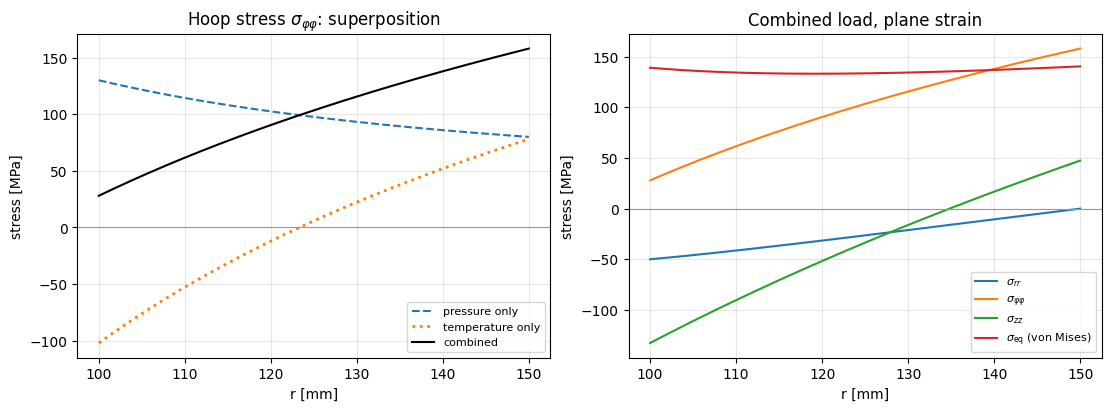

In [8]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
mm = 1e3 * rr
ax1.plot(mm, hoop_pressure, "--", label="pressure only")
ax1.plot(mm, hoop_thermal, ":", lw=2, label="temperature only")
ax1.plot(mm, s["sigma_pp"], "k", label="combined")
ax1.set(title=r"Hoop stress $\sigma_{\varphi\varphi}$: superposition", xlabel="r [mm]", ylabel="stress [MPa]")
labels = {"sigma_rr": r"$\sigma_{rr}$", "sigma_pp": r"$\sigma_{\varphi\varphi}$", "sigma_zz": r"$\sigma_{zz}$",
          "sigma_eq": r"$\sigma_\mathrm{eq}$ (von Mises)"}
for key, label in labels.items():
    ax2.plot(mm, s[key], label=label)
ax2.set(title="Combined load, plane strain", xlabel="r [mm]", ylabel="stress [MPa]")
for ax in (ax1, ax2):
    ax.axhline(0, color="0.6", lw=0.8)
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
plt.show()

**Reading the plots.** Internal pressure alone puts the bore under the largest tensile hoop stress. Heating from the inside makes the
hot inner layer want to expand more than the cooler outer layer allows, which adds compressive hoop stress at the bore and tension
near the outer surface. In this example the two effects partly cancel at $r_i$: the peak von Mises stress drops from about 157 MPa
(pressure only, at the bore) to about 140 MPa, and moves to the outer surface.